In [1]:
import numpy as np
import os

## Load hardware data

In [2]:
from z2hex.geometry import HeavyHexLattice

lattice_dims = (3, 7)
lattice = HeavyHexLattice(*lattice_dims)
J = 0
h = 0
lamb = 1
final_time = 7.5
dt = 0.25
steps = 60
desired_error = 1e-2
string = [27, 26, 24, 22, 33, 41, 43, 45, 53, 64, 62, 60, 71, 79, 81, 83, 91, 102, 100, 98, 109, 117, 119, 121, 122] # Benchmark

In [3]:
import load_data as load
import pickle

# [hardware_datas_em, hardware_datas_trotter, hardware_datas_contour, hardware_datas_1d], [tn_observables_nm, tn_observables_1d] = load.load_benchmark_data()

filenames = [
    "/Users/cobos/MEGA/Doctorado/2nd year/IBM hardware execution/CodeOcean/data/curated_data/z2hexquench_curated_data_ibm_basquecountry_px_3_py_7_maxt_7.5_dt_0.25_steps_60_J_0.0000_h_0.0000_lamb_1.0000_g_None_shots_480000_fqb_None_string_27-26-24-22-33-41-43-45-53-64_xbasis_False_dd_False_pt_False_ft_1_pODR_True_confidence_0.7.pkl",
    "/Users/cobos/MEGA/Doctorado/2nd year/IBM hardware execution/CodeOcean/data/curated_data/z2hexquench_curated_data_ibm_basquecountry_px_3_py_7_maxt_7.5_dt_0.25_steps_60_J_0.0000_h_0.0000_lamb_1.0000_g_None_shots_480000_fqb_None_string_27-26-24-22-33-41-43-45-53-64_xbasis_False_dd_False_pt_True_ft_1_pODR_True_confidence_0.7.pkl",
    "/Users/cobos/MEGA/Doctorado/2nd year/IBM hardware execution/CodeOcean/data/curated_data/z2hexquench_curated_data_ibm_basquecountry_px_3_py_7_maxt_7.5_dt_0.25_steps_60_J_0.0000_h_0.0000_lamb_1.0000_g_zero_mean_shots_480000_fqb_None_string_27-26-24-22-33-41-43-45-53-64_xbasis_False_dd_False_pt_False_ft_1_pODR_True_confidence_0.7.pkl",
    "/Users/cobos/MEGA/Doctorado/2nd year/IBM hardware execution/CodeOcean/data/curated_data/z2hexquench_curated_data_ibm_basquecountry_px_3_py_7_maxt_7.5_dt_0.25_steps_60_J_0.0000_h_0.0000_lamb_1.0000_g_zero_mean_shots_480000_fqb_None_string_27-26-24-22-33-41-43-45-53-64_xbasis_False_dd_False_pt_True_ft_1_pODR_True_confidence_0.7.pkl"
]

hardware_datas_em = []

for filename in filenames:
    with open(filename, "rb") as f:
        hardware_datas_em.append(pickle.load(f))

# Trotter data
filepaths_trotter = ["../data/curated_data/Trotter benchmark data/dt_0.1.pkl", "../data/curated_data/Trotter benchmark data/dt_0.125.pkl", "../data/curated_data/Trotter benchmark data/dt_0.15.pkl", "../data/curated_data/Trotter benchmark data/dt_0.175.pkl", "../data/curated_data/Trotter benchmark data/dt_0.2.pkl"]
hardware_datas_trotter = []
for filepath in filepaths_trotter:
    with open(filepath, "rb") as f:
        hardware_datas_trotter.append(pickle.load(f))

# 1D data
filepaths_hardware_contour = ["../data/curated_data/1D_benchmark_data/m_5_g_0.8.pkl", "../data/curated_data/1D_benchmark_data/m_5_g_0.01.pkl"]
hardware_datas_contour = []
for filepath in filepaths_hardware_contour:
    with open(filepath, "rb") as f:
        hardware_datas_contour.append(pickle.load(f))

filepaths_hardware_1d = ["../data/curated_data/1D_benchmark_data/2nd_run_close/m_5_g_0.8_nonan.pkl", "../data/curated_data/1D_benchmark_data/2nd_run_close/m_5_g_0.8_clifford_nonan.pkl", "../data/curated_data/1D_benchmark_data/2nd_run_close/m_5_g_0.01.pkl", "../data/curated_data/1D_benchmark_data/2nd_run_close/m_5_g_0.01_clifford.pkl"]
hardware_datas_1d = []
for filepath in filepaths_hardware_1d:
    with open(filepath, "rb") as f:
        hardware_datas_1d.append(pickle.load(f))

# TN data
filename_tn_nm = "../data/tn/benchmark/trotter/data.txt"
filenames_tn_1d = ["../data/tn/benchmark/1d/tn_m_5_g_0.8.npy", "../data/tn/benchmark/1d/tn_m_5_g_0.01.npy"]

tn_observables_nm = np.loadtxt(filename_tn_nm)
tn_observables_1d = []
for filename in filenames_tn_1d:
    tn_observables_1d.append(np.load(filename))

## Plots

In [4]:
from utils.postselection_multithreaded import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
from z2hex.operators import local_pauli_z, postselection_operators
import matplotlib.pyplot as plt
from pymatching import Matching

def plot_individual_qubits_observable_evolution_em(ax, observable_matrix, observable_confidence_matrix=None, function_over=None, ylabel=None, cmap=None, x_ticks=None, x_label=None, y_lim=None, markers=None, funclabels=None, title="", legend=True, legend_fontsize=None, data_linewidth=1.5, filepath=None):
    observable_matrix = np.array(observable_matrix)
    if observable_confidence_matrix is not None:
        observable_confidence_matrix = np.array(observable_confidence_matrix)
        if observable_matrix.shape != observable_confidence_matrix.shape[:-1]:
            raise ValueError("Observable matrix and standard deviation matrix must have the same shape")
    if funclabels is not None:
        try:
            if len(funclabels) != (observable_matrix.shape[1] + (1 if function_over is not None else 0)):
                print(observable_matrix.shape[1])
                print(observable_matrix.shape[1] + (1 if function_over is not None else 0))
                raise ValueError("funclabels must have the same length as the number of qubits")
        except TypeError:
            raise ValueError("funclabels must have the same length as the number of qubits")
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")

    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)
        x = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix.shape[0])
    else:
        x = np.arange(observable_matrix.shape[0])
    if function_over is not None:
        if callable(function_over):
            xf = np.linspace(x[0], x[-1], 500)
            ax.plot(xf, function_over(xf), "-", color=cmap((observable_matrix.shape[1] % 8)), label=funclabels[observable_matrix.shape[1]] if funclabels is not None else f"Function", linewidth=2.5)
        else:
            x_func = np.linspace(x[0], x[-1], len(function_over))
            ax.plot(x_func, function_over, "-", color=cmap((observable_matrix.shape[1] % 8)), label=funclabels[observable_matrix.shape[1]] if funclabels is not None else f"Function", linewidth=2.5)
    for i in range(observable_matrix.shape[1]):
        color = cmap((i % 8))
        y = observable_matrix[:, i]
        if observable_confidence_matrix is not None:
            upper_error_bound_mask = np.less(y.reshape((len(y), 1)), observable_confidence_matrix[:, i, :])
            lower_error_bound_mask = np.greater(y.reshape((len(y), 1)), observable_confidence_matrix[:, i, :])
            consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
            upper_error = observable_confidence_matrix[:, i, 1][consistency_mask] - y[consistency_mask]
            lower_error = y[consistency_mask] - observable_confidence_matrix[:, i, 0][consistency_mask]
            yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
            yerr[consistency_mask, 0] = lower_error
            yerr[consistency_mask, 1] = upper_error
            ax.fill_between(x, observable_confidence_matrix[:, i, 0], observable_confidence_matrix[:, i, 1], color=cmap(i), alpha=0.3)
            ax.plot(x, observable_matrix[:, i], f"{markers[i]}", markersize=10, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")
        else:
            ax.plot(x, y, f"{markers[i]}--", markersize=8, linewidth=data_linewidth, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(ylabel, labelpad=8)
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix)
        max_data = np.nanmax(observable_matrix)
        ax.set_ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    elif y_lim is not None:
        ax.set_ylim(y_lim)
    if title:
        ax.set_title(title, pad=10, fontdict={"size":26})
    if legend: ax.legend(loc="best", fontsize=36 if legend_fontsize is None else legend_fontsize)

def get_flip_distributions(samples_dict):
    observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
    postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)
    
    postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

    postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
    decoder = Matching(postselection_mask)

    states = np.array([[int(c) for c in string] for string in samples_dict.keys()])
    state_counts = np.array(list(samples_dict.values()))
    states_syndromes = (states @ postselection_mask.T) % 2
    predicted_flips = decoder.decode_batch(states_syndromes)
    nflips = predicted_flips.sum(axis=1)
    unique_nflips = np.unique(nflips)
    this_flip_counts = {}
    this_total_nflips = 0
    for nf in unique_nflips:
        this_counts = np.sum(state_counts[np.equal(nflips, nf)])
        this_flip_counts[nf] = this_counts
        this_total_nflips += this_counts
    this_mean = 0
    for nf, counts in this_flip_counts.items():
        this_mean += nf*counts/this_total_nflips
    standard_distributions = 0
    for nf, counts in this_flip_counts.items():
        standard_distributions += (nf - this_mean)**2 * counts/this_total_nflips
    standard_distributions = np.sqrt(standard_distributions)

    return this_mean, standard_distributions

def plot_mean_flips(ax, samples_dicts, color, final_time, marker="o", data_filepath=""):
    observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
    postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)
    
    postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

    postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
    decoder = Matching(postselection_mask)

    steps = len(samples_dicts)

    if os.path.exists(data_filepath):
        distribution_means, standard_distributions = np.loadtxt(data_filepath)
    else:
        distribution_means = np.zeros(steps)
        standard_distributions = np.zeros(steps)
        for i in range(len(samples_dicts)):
            combined_samples_dict = samples_dicts[i].copy()
            if combined_samples_dict == {}:
                distribution_means[i] = np.nan
                standard_distributions[i] = np.nan
            else:
                states = np.array([[int(c) for c in string] for string in combined_samples_dict.keys()])
                state_counts = np.array(list(combined_samples_dict.values()))
                states_syndromes = (states @ postselection_mask.T) % 2
                predicted_flips = decoder.decode_batch(states_syndromes)
                nflips = predicted_flips.sum(axis=1)
                unique_nflips = np.unique(nflips)
                this_flip_counts = {}
                this_total_nflips = 0
                for nf in unique_nflips:
                    this_counts = np.sum(state_counts[np.equal(nflips, nf)])
                    this_flip_counts[nf] = this_counts
                    this_total_nflips += this_counts
                this_mean = 0
                for nf, counts in this_flip_counts.items():
                    this_mean += nf*counts/this_total_nflips
                distribution_means[i] = this_mean
                for nf, counts in this_flip_counts.items():
                    standard_distributions[i] += (nf - this_mean)**2 * counts/this_total_nflips
                standard_distributions[i] = np.sqrt(standard_distributions[i])
                if data_filepath is not None:
                    np.savetxt(data_filepath, np.array([distribution_means, standard_distributions]))

    x = np.linspace(0, final_time, steps)
    x_ticks = np.round(np.linspace(0, final_time, 7)).astype(int)
    ax.fill_between(x, distribution_means - standard_distributions, distribution_means + standard_distributions, color=color, alpha=0.3)
    ax.plot(x, distribution_means, f"{marker}--", markersize=10, markeredgecolor="black", color=color)

def plot_individual_qubits_observable_evolution_trotter(ax, final_times, observable_matrix, observable_confidence_matrix=None, function_over=None, ylabel=None, cmap=None, x_ticks=None, x_label=None, y_lim=None, fmt="", funclabels=None, title="", legend=True, legend_fontsize=None, data_linewidth=1.5, filepath=None):
    observable_matrix = np.array(observable_matrix)
    if observable_confidence_matrix is not None:
        observable_confidence_matrix = np.array(observable_confidence_matrix)
        if observable_matrix.shape != observable_confidence_matrix.shape[:-1]:
            print(observable_matrix.shape)
            print(observable_confidence_matrix.shape)
            raise ValueError("Observable matrix and standard deviation matrix must have the same shape")
    if funclabels is not None:
        try:
            if len(funclabels) != (observable_matrix.shape[1] + (1 if function_over is not None else 0)):
                print(observable_matrix.shape[1])
                print(observable_matrix.shape[1] + (1 if function_over is not None else 0))
                raise ValueError("funclabels must have the same length as the number of qubits")
        except TypeError:
            raise ValueError("funclabels must have the same length as the number of qubits")
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")

    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)

    xs = [np.linspace(0, final_time, observable_matrix.shape[0]) for final_time in final_times]
    if function_over is not None:
        if callable(function_over):
            xf = np.linspace(xs[-1][0], xs[-1][-1], 500)
            ax.plot(xf, function_over(xf), "-", color=cmap((observable_matrix.shape[1] % 8)), label=funclabels[observable_matrix.shape[1]] if funclabels is not None else f"Function", linewidth=2.5)
        else:
            x_func = np.linspace(xs[-1][0], xs[-1][-1], len(function_over))
            ax.plot(x_func, function_over, "-", color=cmap((0)), label=funclabels[observable_matrix.shape[1]] if funclabels is not None else f"Function", linewidth=2.5)
    for i in range(observable_matrix.shape[1]):
        color = cmap(i+1)
        y = observable_matrix[:, i]
        if observable_confidence_matrix is not None:
            upper_error_bound_mask = np.less(y.reshape((len(y), 1)), observable_confidence_matrix[:, i, :])
            lower_error_bound_mask = np.greater(y.reshape((len(y), 1)), observable_confidence_matrix[:, i, :])
            consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
            upper_error = observable_confidence_matrix[:, i, 1][consistency_mask] - y[consistency_mask]
            lower_error = y[consistency_mask] - observable_confidence_matrix[:, i, 0][consistency_mask]
            yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
            yerr[consistency_mask, 0] = lower_error
            yerr[consistency_mask, 1] = upper_error
            ax.fill_between(xs[i], observable_confidence_matrix[:, i, 0], observable_confidence_matrix[:, i, 1], color=cmap(i+1), alpha=0.3)
            ax.plot(xs[i], observable_matrix[:, i], "o", markersize=10, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")
        else:
            ax.plot(xs[i], y, "o--" if fmt is None else fmt, markersize=8, linewidth=data_linewidth, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(ylabel, labelpad=3)
    ax.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix) 
        max_data = np.nanmax(observable_matrix)
        ax.set_ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    elif y_lim is not None:
        ax.set_ylim(y_lim)
    if title:
        ax.set_title(title, pad=10, fontdict={"size":26})
    if legend: ax.legend(loc="best", ncol=2, columnspacing=0.5, handlelength=0.3, fontsize=36 if legend_fontsize is None else legend_fontsize)

def matter_x_t_plot(ax, site_gauge_z_matrix, cbar_range=None, nxticks=5, ylabel=None, y_ticks=None, cbar=True, cbar_matter_label=r"$(1 - \langle Z \rangle)/2$"):
    x = np.arange(1, site_gauge_z_matrix.shape[1]+1)
    if y_ticks is not None:
        y = np.linspace(y_ticks[0], y_ticks[-1], site_gauge_z_matrix.shape[0])
    else:
        y = np.linspace(0, site_gauge_z_matrix.shape[0]-1, site_gauge_z_matrix.shape[0])
    X, Y = np.meshgrid(x, y)
    X_matter = X[::-1, 0::2]
    Y_matter = Y[::-1, 0::2]
    Z_matter = ((1 - site_gauge_z_matrix[::-1, 0::2])/2)

    if cbar_range is None:
        imm = ax.pcolormesh(X_matter, Y_matter, Z_matter, cmap="inferno")
    else:
        imm = ax.pcolormesh(X_matter, Y_matter, Z_matter, cmap="inferno", vmax=cbar_range[1], vmin=cbar_range[0], edgecolors="face")
        if cbar:
            cbarm = plt.colorbar(imm, ax=ax)
            cbarm.ax.set_ylabel(cbar_matter_label, labelpad=10)

    ax.set_ylabel(ylabel, labelpad=15)

    ax.invert_yaxis()
    return cbarm

def error_plot(ax, observable_matrices_h, observable_matrices_tn, colors, markers, x_label=r"$\lambda t$", x_ticks=None, funclabels=None, legend=True, legend_fontsize=None):
    observable_matrices_h = np.array(observable_matrices_h)
    observable_matrices_tn = np.array(observable_matrices_tn)

    if (shape := observable_matrices_h.shape) != observable_matrices_tn.shape:
        raise ValueError("Observable matrices must have the same shape")
    
    if len(colors) != shape[0]:
        raise ValueError("Colors must have the same length as the number of observables")
    
    if len(markers) != shape[0]:
        raise ValueError("Markers must have the same length as the number of observables")
    
    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)
        x = np.linspace(x_ticks[0], x_ticks[-1], shape[1])
    else:
        x = np.arange(shape[1])

    for i in range(shape[0]):
        color = colors[i]
        h_obs = observable_matrices_h[i, :]
        tn_obs = observable_matrices_tn[i, :]
        error = np.abs(h_obs - tn_obs)
        mean_error = np.nanmean(error, axis=1)
        ax.plot(x, mean_error, markers[i] + "--", markersize=10, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Observables {i}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(r"Mean error", labelpad=-5)
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if legend:
        ax.legend(loc="best", fontsize=15 if legend_fontsize is None else legend_fontsize)

# Figure

/var/folders/zt/hqjs857x0ts5mnnl_w2438ww0000gn/T/ipykernel_7281/1905124499.py:200: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


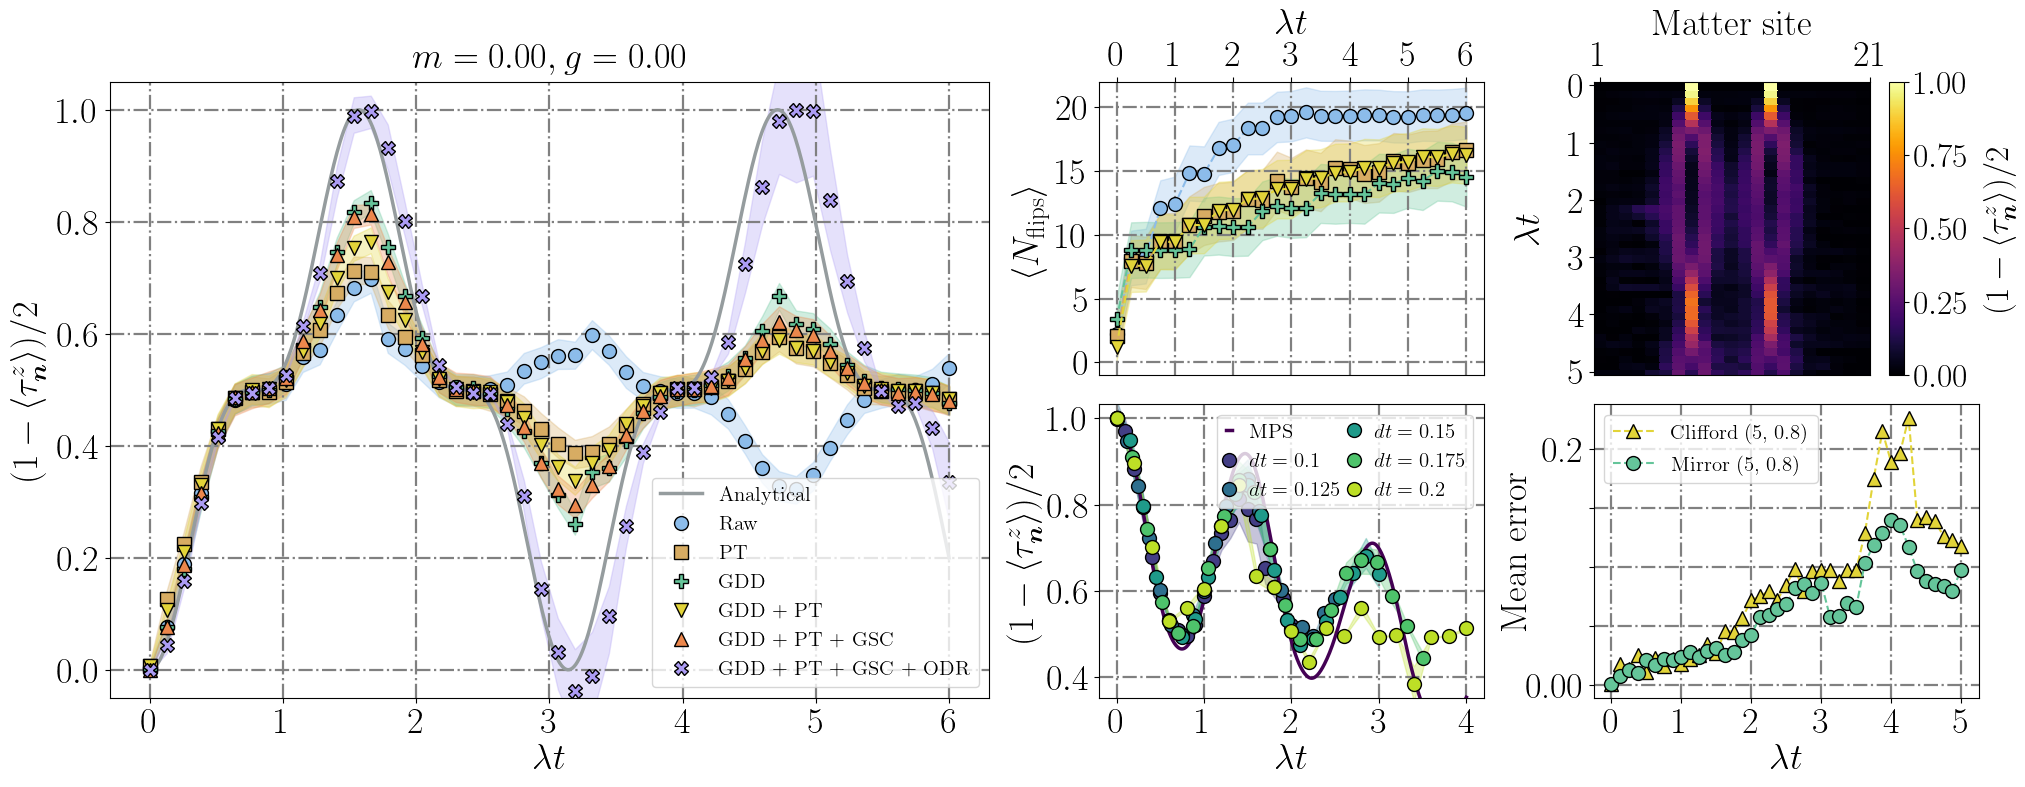

In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import ScalarFormatter
import matplotlib.pyplot as plt

colors = ["#8CBCEA", "#65C59A", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]
em_colors = [colors[0]] + [colors[6]] + colors[1:4] + [colors[7]] + [colors[-1]]
# em_colors = (colors[:4] + [colors[7]] + [colors[-1]])
trotter_colors = colors[-6:][::-1]
colors_odr = (colors[1], colors[2])

plt.rc("text", usetex=True)
plt.rc("text.latex", preamble=r"\usepackage{mathtools}")
plt.rc("font", size=26, family="serif", weight="bold")

fig = plt.figure(figsize=(21, 8))

nxlabels = 5
margin = 0.05

gs = GridSpec(2, 8, figure=fig, wspace=0.8, hspace=0.1, left=0.08, right=0.97)
ax1 = fig.add_subplot(gs[:, :4])
ax2 = fig.add_subplot(gs[0, 4:6])
ax3 = fig.add_subplot(gs[1, 4:6])
ax4 = fig.add_subplot(gs[0, 6::])
ax6 = fig.add_subplot(gs[1, 6::])

# Figure 1
qubit = 63

plot_upto_time = 6
plot_upto = int(np.ceil(steps*plot_upto_time/final_time))
plot_step = 1

cmap = lambda x: em_colors[x] # plt.get_cmap("GnBu")((1.4*(x)+2.8)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}$"
legend = False
x_ticks = np.round(np.linspace(0, plot_upto_time, 7))
x_label = r"$\lambda t$"
y_label = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
legend_fontsize = 15
y_lim = "data"

funclabels = [
    "Raw",
    "PT",
    "GDD",
    "GDD + PT",
    "GDD + PT + GSC",
    "GDD + PT + GSC + ODR",
    "Analytical"
]

hardware_observables_to_plot = np.column_stack([hdata[0][3][:, qubit] for hdata in hardware_datas_em] + [hardware_datas_em[-1][0][1][:, qubit], hardware_datas_em[-1][0][0][:, qubit]])
# hardware_observables_to_plot = np.column_stack([observables[3][:, qubit]] + [hdata[0][3][:, qubit] for hdata in hardware_datas_em] + [hardware_datas_em[-1][0][1][:, qubit], hardware_datas_em[-1][0][0][:, qubit]])

hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas_em) + 2, 2))
# hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas_em) + 3, 2))
# hardware_observables_confidences_to_plot[:, 0, :] = observables_confidence[3][:, qubit, :]
for i, hdata in enumerate(hardware_datas_em):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][3][:, qubit, :]
hardware_observables_confidences_to_plot[:, -2, :] = hardware_datas_em[-1][1][1][:, qubit, :]    
hardware_observables_confidences_to_plot[:, -1, :] = hardware_datas_em[-1][1][0][:, qubit, :]

hardware_observables_to_plot = hardware_observables_to_plot[:plot_upto:plot_step, :]
hardware_observables_confidences_to_plot = hardware_observables_confidences_to_plot[:plot_upto:plot_step, :, :]

hardware_observables_to_plot = (1 - hardware_observables_to_plot) / 2
hardware_observables_confidences_to_plot = (1 - hardware_observables_confidences_to_plot) / 2

plot_individual_qubits_observable_evolution_em(ax1, hardware_observables_to_plot, hardware_observables_confidences_to_plot, lambda x: (1 - np.cos(2*x)**3)/2, markers=["o", "s", "P", "v", "^", "X"], x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, y_lim=y_lim)
ax1.set_ylim([-0.05, 1.05])

# Figure 2

from utils.postselection_multithreaded import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
from z2hex.operators import local_pauli_z, postselection_operators
import matplotlib.pyplot as plt
from pymatching import Matching

plot_final_time = 6
cmap = lambda x: em_colors[x] #plt.get_cmap("GnBu")((1.4*(x)+2.8)/8)
x_ticks = np.round(np.linspace(0, plot_final_time, 7))

markers = ["o", "s", "P", "v"]

plt.rc("text", usetex=True)
plt.rc("font", size=24, family="serif", weight="bold")
# all_samples_dicts = [hdata[2][0][0][:2*int(np.ceil(plot_final_time//dt))+1:2] if i != 2 else hdata[2][0][0][:int(np.ceil(plot_final_time//dt))+1] for i, hdata in enumerate(hardware_datas_em)]
all_samples_dicts = [hdata[2][0][0][:2*int(np.ceil(plot_final_time//dt))+1:2] for i, hdata in enumerate(hardware_datas_em)]

observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

for i, samples in enumerate(all_samples_dicts):
    data_filepath = f"../data/curated_data/flip_distributions/flip_distribution_{i}.txt"
    color = cmap(i)
    plot_mean_flips(ax2, samples, color, plot_final_time, marker=markers[i], data_filepath=data_filepath)

ax2.set_xticks(x_ticks)
ax2.set_xlabel(r"$\lambda t$")
ax2.set_ylabel(r"$\langle N_{\mathrm{flips}} \rangle$", labelpad=5)
ax2.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
ax2.xaxis.set_ticks_position("top")
ax2.xaxis.set_label_position("top")
ax2.set_ylim([-1, 22])
ax2.set_yticks([0, 5, 10, 15, 20])

# Figure 3
qubit = 4

plot_upto_times = [2, 2.5, 3, 3.5, 4]
tn_dt = 0.01
plot_upto = int(np.ceil(plot_upto_times[-1]/tn_dt))
plot_step = 1

# cmap = lambda x: plt.get_cmap("GnBu")((1.4*(x)+2.8)/8)
# cmap = lambda x: plt.get_cmap("plasma_r")((1 - 0.1)*x/len(plot_upto_times) + 0.1)
cmap = lambda x: trotter_colors[x] #plt.get_cmap("viridis")((0.9)*x/len(plot_upto_times))
cmap = lambda x: plt.get_cmap("viridis")((0.9)*x/len(plot_upto_times))
cmap_discrete = ListedColormap([cmap(i) for i in range(len(plot_upto_times))])
markers = None #["v", "^"]
title = None
legend = True
x_ticks = np.round(np.linspace(0, plot_upto_time, 7))
x_label = r"$\lambda t$"
y_label = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
legend_fontsize = 15
y_lim = "data"

funclabels = [
    r"$dt = 0.1$",
    r"$dt = 0.125$",
    r"$dt = 0.15$",
    r"$dt = 0.175$",
    r"$dt = 0.2$",
    "MPS"
]

hardware_observables_to_plot = np.column_stack([hdata[0][0][:, qubit] for hdata in hardware_datas_trotter])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas_trotter), 2))
for i, hdata in enumerate(hardware_datas_trotter):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]

tn_observables_nm_to_plot = tn_observables_nm[:plot_upto:plot_step, qubit]

hardware_observables_to_plot = (1 - hardware_observables_to_plot) / 2
hardware_observables_confidences_to_plot = (1 - hardware_observables_confidences_to_plot) / 2
tn_observables_nm_to_plot = (1 - tn_observables_nm_to_plot) / 2

plot_individual_qubits_observable_evolution_trotter(ax3, plot_upto_times, hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observables_nm_to_plot, fmt="o--", x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend=legend, legend_fontsize=legend_fontsize, y_lim=y_lim)

# Figure 4

cbar_matter_label=r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
x_ticks = [1, 42]
x_ticks_labels = [1, 21]
hdt_1d = 0.125
h_final_time_1d = 5
steps = 40
cbar = True
y_label = r"$\lambda t$"

pdata = hardware_datas_contour[0][0][0]
pdata[np.isnan(pdata)] = 1
cbar = matter_x_t_plot(ax4, pdata, ylabel=y_label, cbar_range=[0, 1], nxticks=2, cbar=cbar, cbar_matter_label=cbar_matter_label)
cbar_ogposition = cbar.ax.get_position()
cbar.ax.set_position([cbar_ogposition.x0 - 0.015, cbar_ogposition.y0, cbar_ogposition.width, cbar_ogposition.height])
ax4.xaxis.set_ticks_position("top")
ax4.xaxis.set_label_position("top")
ax4.set_xticks(x_ticks, x_ticks_labels)
ax4.set_xlabel("Matter site")
ax4.set_yticks(np.linspace(0, steps, 6), list(np.arange(0, 6)))
ax4_ogpos = ax4.get_position()
ax4.set_position([ax4_ogpos.x0, ax4_ogpos.y0, ax4_ogpos.width - 0.015, ax4_ogpos.height])

# Figure 5

cmap = plt.get_cmap("Set2")
colors = colors_odr[::-1]
markers = ["o", "^"][::-1]
x_ticks = np.arange(0, 6)
x_label = r"$\lambda t$"

labels = [
    "Mirror (5, 0.8)",
    "Clifford (5, 0.8)",
][::-1]

tndt_1d = 0.0125
tnstep_1d = int(np.ceil(hdt_1d / tndt_1d))
hobs_1d = [hardware_datas_1d[i][0][0] for i in range(len(hardware_datas_1d[:2]))][::-1]
tnobs_1d = [tn_observables_1d[0][::tnstep_1d, :]]*2

error_plot(ax6, hobs_1d, tnobs_1d, colors, markers, x_label, x_ticks, labels, legend=True, legend_fontsize=15)

ax6.set_yticks([0, 0.05, 0.1, 0.15, 0.20], ["0.00", "", "", "", 0.2])

plt.tight_layout()
plt.savefig("/results/error_mitigation_data.svg", dpi=300, facecolor="none")

In [6]:
tn_observables_nm_to_plot

array([1.       , 0.9997005, 0.998804 , 0.9973145, 0.9952385, 0.992584 ,
       0.989363 , 0.985587 , 0.9812715, 0.9764315, 0.971084 , 0.965246 ,
       0.9589355, 0.9521715, 0.944973 , 0.9373575, 0.929345 , 0.9209535,
       0.912202 , 0.9031085, 0.8936925, 0.883972 , 0.873968 , 0.863699 ,
       0.853186 , 0.8424505, 0.8315145, 0.8204015, 0.809134 , 0.797738 ,
       0.7862375, 0.7746585, 0.763028 , 0.7513715, 0.739716 , 0.728088 ,
       0.716513 , 0.705017 , 0.693624 , 0.6823585, 0.671243 , 0.660299 ,
       0.649547 , 0.639005 , 0.6286905, 0.6186195, 0.608806 , 0.5992635,
       0.5900035, 0.581037 , 0.5723725, 0.564018 , 0.555982 , 0.5482695,
       0.540887 , 0.5338375, 0.527126 , 0.520755 , 0.5147275, 0.5090445,
       0.503708 , 0.4987195, 0.49408  , 0.48979  , 0.48585  , 0.482261 ,
       0.4790235, 0.4761385, 0.473607 , 0.4714295, 0.469608 , 0.4681435,
       0.467038 , 0.4662935, 0.4659115, 0.465895 , 0.4662465, 0.466969 ,
       0.4680645, 0.469536 , 0.4713855, 0.4736155, 

## Legend

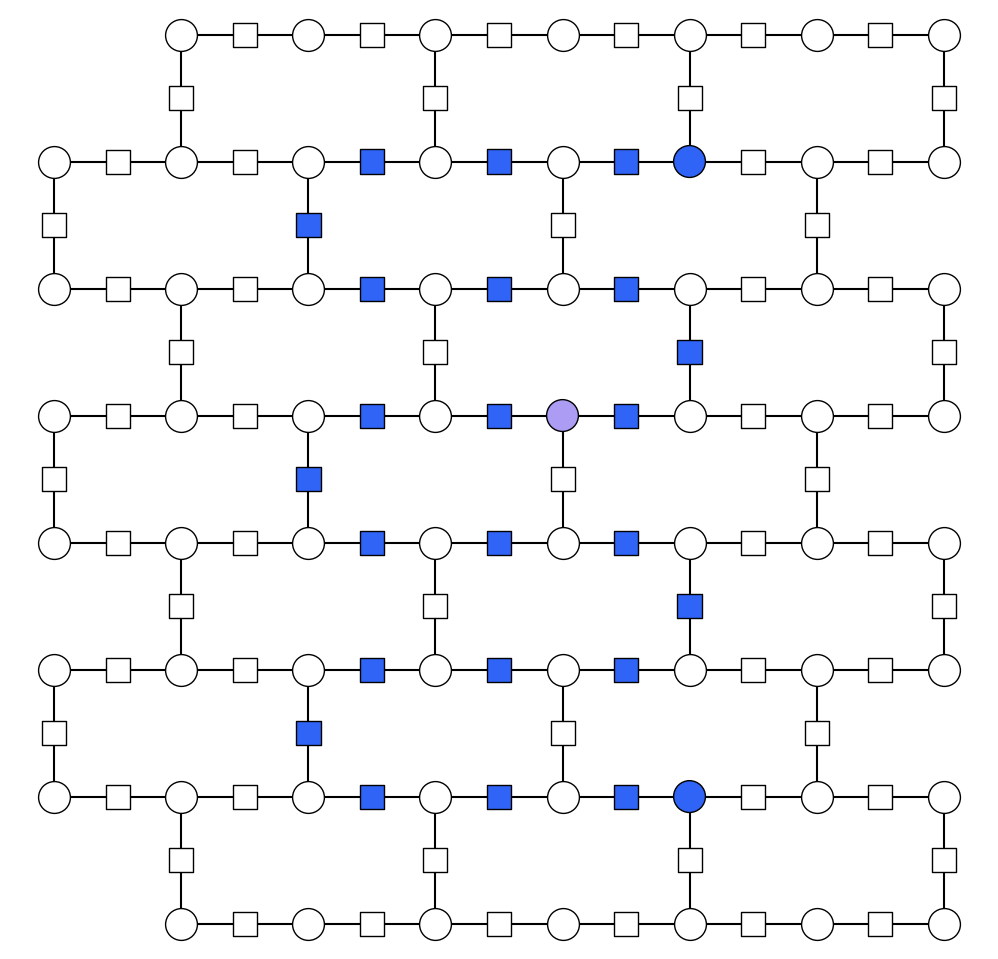

In [ ]:
conf_qubits = [63] + string

lattice.plot_highlighted_qubits(conf_qubits, colors=["#AC9CF4"]+["#2f64f7"]*len(string), number_highlighted=False, filepath="/results/em_config_legend.svg", number_qubits=False)